# Business Case: Aerofit -  Descriptive Statistics & Probability

## 1.**Introduction**

### **What is Aerofit ?**
Aerofit is a leading brand in the field of fitness equipment. Aerofit provides a product range including machines such as treadmills, exercise bikes, gym equipment, and fitness accessories to cater to the needs of all categories of people.
### **Business Problem**
The market research team at AeroFit wants to identify the characteristics of the target audience for each type of treadmill offered by the company, to provide a better recommendation of the treadmills to the new customers. The team decides to investigate whether there are differences across the product with respect to customer characteristics.
###  **Objective**
Create comprehensive customer profiles for each AeroFit treadmill product through descriptive analytics. Develop two-way contingency tables and analyze conditional and marginal probabilities to discern customer characteristics, facilitating improved product recommendations and informed business decisions.



## 2. Exploratory Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import copy

In [2]:
# loading the dataset
df = pd.read_csv('aerofit_treadmill.txt')

In [3]:
df.head()

,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
0,KP281,18,Male,14,Single,3,4,29562,112
1,KP281,19,Male,15,Single,2,3,31836,75
2,KP281,19,Female,14,Partnered,4,3,30699,66
3,KP281,19,Male,12,Single,3,3,32973,85
4,KP281,20,Male,13,Partnered,4,2,35247,47


In [4]:
df.shape

(180, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Product        180 non-null    object
 1   Age            180 non-null    int64 
 2   Gender         180 non-null    object
 3   Education      180 non-null    int64 
 4   MaritalStatus  180 non-null    object
 5   Usage          180 non-null    int64 
 6   Fitness        180 non-null    int64 
 7   Income         180 non-null    int64 
 8   Miles          180 non-null    int64 
dtypes: int64(6), object(3)
memory usage: 12.8+ KB


In [6]:
df.isnull().sum()

,0
Product,0
Age,0
Gender,0
Education,0
MaritalStatus,0
Usage,0
Fitness,0
Income,0
Miles,0


In [7]:
df['Product'].unique()

array(['KP281', 'KP481', 'KP781'], dtype=object)

In [8]:
df.describe(include="all")

,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
count,180,180.000000,180,180.000000,180,180.000000,180.000000,180.000000,180.000000
unique,3,NaN,2,NaN,2,NaN,NaN,NaN,NaN
top,KP281,NaN,Male,NaN,Partnered,NaN,NaN,NaN,NaN
freq,80,NaN,104,NaN,107,NaN,NaN,NaN,NaN
mean,NaN,28.788889,NaN,15.572222,NaN,3.455556,3.311111,53719.577778,103.194444
std,NaN,6.943498,NaN,1.617055,NaN,1.084797,0.958869,16506.684226,51.863605
min,NaN,18.000000,NaN,12.000000,NaN,2.000000,1.000000,29562.000000,21.000000
25%,NaN,24.000000,NaN,14.000000,NaN,3.000000,3.000000,44058.750000,66.000000
50%,NaN,26.000000,NaN,16.000000,NaN,3.000000,3.000000,50596.500000,94.000000
75%,NaN,33.000000,NaN,16.000000,NaN,4.000000,4.000000,58668.000000,114.750000


Observations:



*  There are no missing values in the data.
*  There are 3 unique products in the dataset.
*  KP281 is the most frequent product.
*  Minimum & Maximum age of the person is 18 & 50, mean is 28.79 and 75% of persons have age less than or equal to 33.
*   Most of the people are having 16 years of education i.e. 75% of persons are having education <= 16 years.
*   Out of 180 data points, 104's gender is Male and rest are the female.
*   Standard deviation for Income & Miles is very high. These variables might have the outliers in it.




















## 3.Univariate Analysis

Understanding the distribution of numeric attributes:
1. Age
2. Education
3. Usage
4. Fitness
5. Income
6. Miles

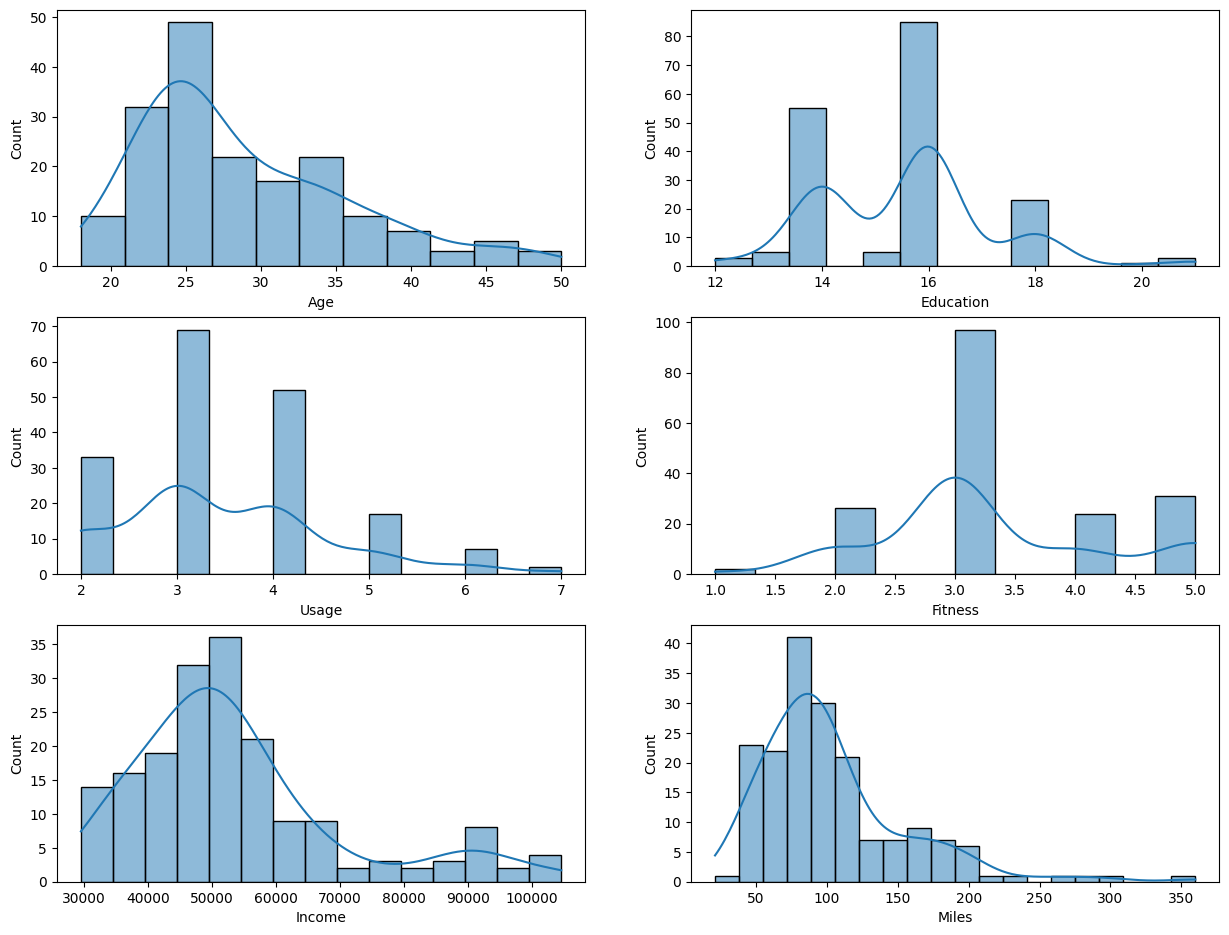

In [9]:
fig, axis = plt.subplots(nrows=3, ncols=2, figsize=(15,8))
fig.subplots_adjust(top=1.2)

sns.histplot(data=df, x="Age", kde=True, ax=axis[0,0])
sns.histplot(data=df, x="Education", kde=True, ax=axis[0,1])
sns.histplot(data=df, x="Usage", kde=True, ax=axis[1,0])
sns.histplot(data=df, x="Fitness", kde=True, ax=axis[1,1])
sns.histplot(data=df, x="Income", kde=True, ax=axis[2,0])
sns.histplot(data=df, x="Miles", kde=True, ax=axis[2,1])
plt.show()

### Outliers detection using BoxPlots

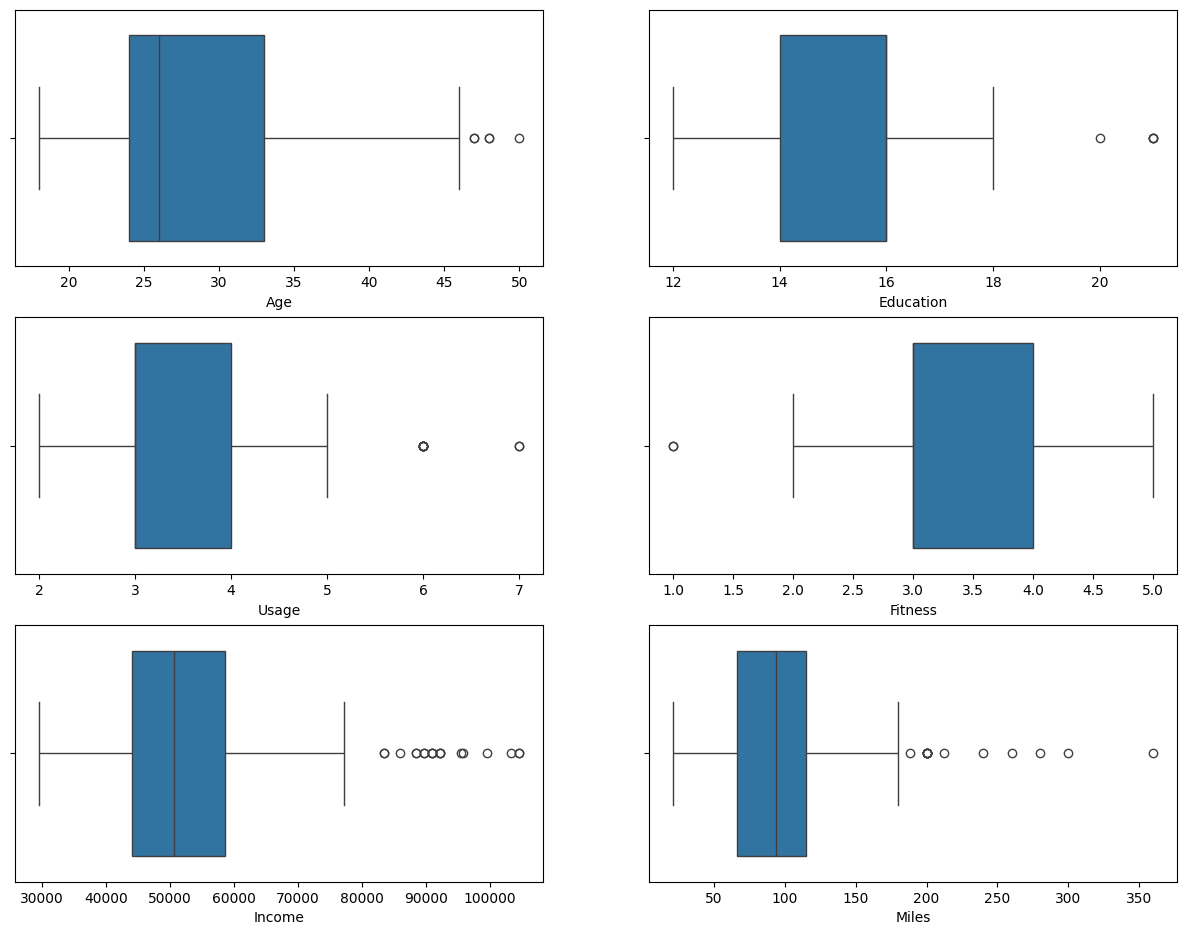

In [10]:
fig, axis = plt.subplots(nrows=3, ncols=2, figsize=(15, 8))
fig.subplots_adjust(top=1.2)

sns.boxplot(data=df, x="Age", orient='h', ax=axis[0,0])
sns.boxplot(data=df, x="Education", orient='h', ax=axis[0,1])
sns.boxplot(data=df, x="Usage", orient='h', ax=axis[1,0])
sns.boxplot(data=df, x="Fitness", orient='h', ax=axis[1,1])
sns.boxplot(data=df, x="Income", orient='h', ax=axis[2,0])
sns.boxplot(data=df, x="Miles", orient='h', ax=axis[2,1])
plt.show()

###Obervation

Even from the boxplots it is quite clear that:

- Age, Education and Usage are having very few outliers.
- While Income and Miles are having more outliers.

#### Understanding the distribution of the data for the qualitative attributes:

1. Product
2. Gender
3. MaritalStatus

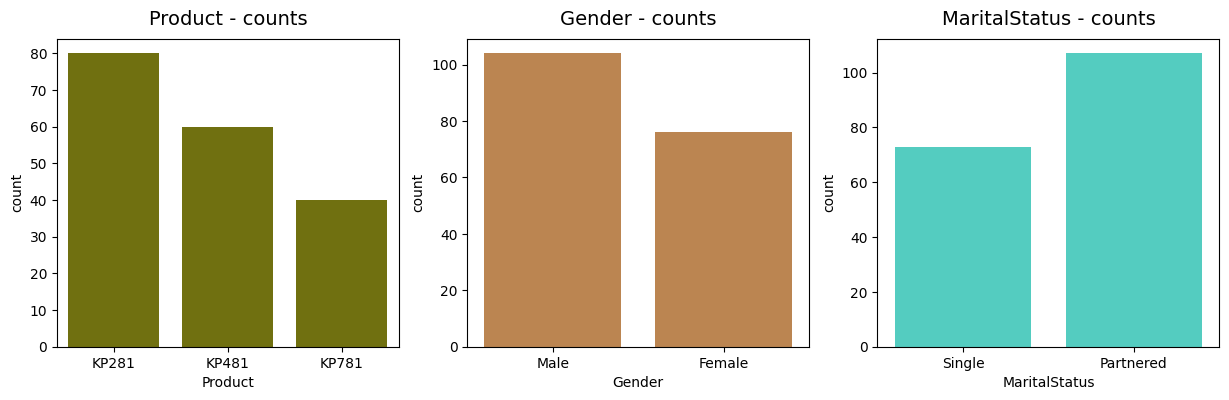

In [11]:
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))
sns.countplot(data=df, x='Product', ax=axs[0],color='olive')
sns.countplot(data=df, x='Gender', ax=axs[1],color='peru')
sns.countplot(data=df, x='MaritalStatus', ax=axs[2],color='turquoise')

axs[0].set_title("Product - counts", pad=10, fontsize=14)
axs[1].set_title("Gender - counts", pad=10, fontsize=14)
axs[2].set_title("MaritalStatus - counts", pad=10, fontsize=14)
plt.show()

#### Obervations

- KP281 is the most frequent product.
- Thare are more Males in the data than Females.
- More Partnered persons are there in the data.

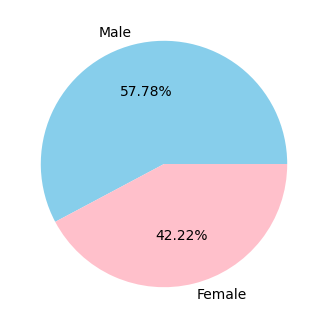

In [12]:
plt.figure(figsize=(4,4))
plt.pie(df['Gender'].value_counts().values,labels = df['Gender'].value_counts().index,autopct = '%.2f%%',colors=['skyblue', 'pink' ])
plt.show()

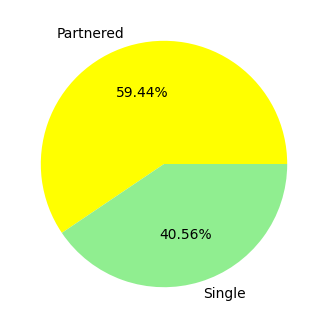

In [13]:
plt.figure(figsize=(4,4))
plt.pie(df['MaritalStatus'].value_counts().values,labels = df['MaritalStatus'].value_counts().index,autopct = '%.2f%%',colors=['yellow', 'lightgreen'])
plt.show()

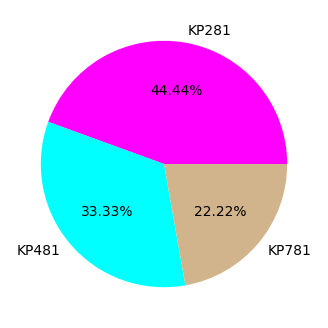

In [14]:
plt.figure(figsize=(4,4))
plt.pie(df['Product'].value_counts().values,labels = df['Product'].value_counts().index,autopct = '%.2f%%',colors=['magenta', 'cyan','tan'])
plt.show()

To be precise - normalized count for each variable is shown below

In [15]:
df1 = df[['Product', 'Gender', 'MaritalStatus']].melt()
df1.groupby(['variable', 'value'])[['value']].count() / len(df)

value
variable      value              
Gender        Female     0.422222
              Male       0.577778
MaritalStatus Partnered  0.594444
              Single     0.405556
Product       KP281      0.444444
              KP481      0.333333
              KP781      0.222222

#### Obervations
- **Product**
    - 44.44% of the customers have purchased **KP2821** product.
    - 33.33% of the customers have purchased **KP481** product.
    - 22.22% of the customers have purchased **KP781** product.
    
    
- **Gender**
    - 57.78% of the customers are **Male**.
    
    
- **MaritalStatus**
    - 59.44% of the customers are **Partnered**.

## 4.Bivariate Analysis

#### Checking if features : Gender or MaritalStatus have any effect on the product purchased.

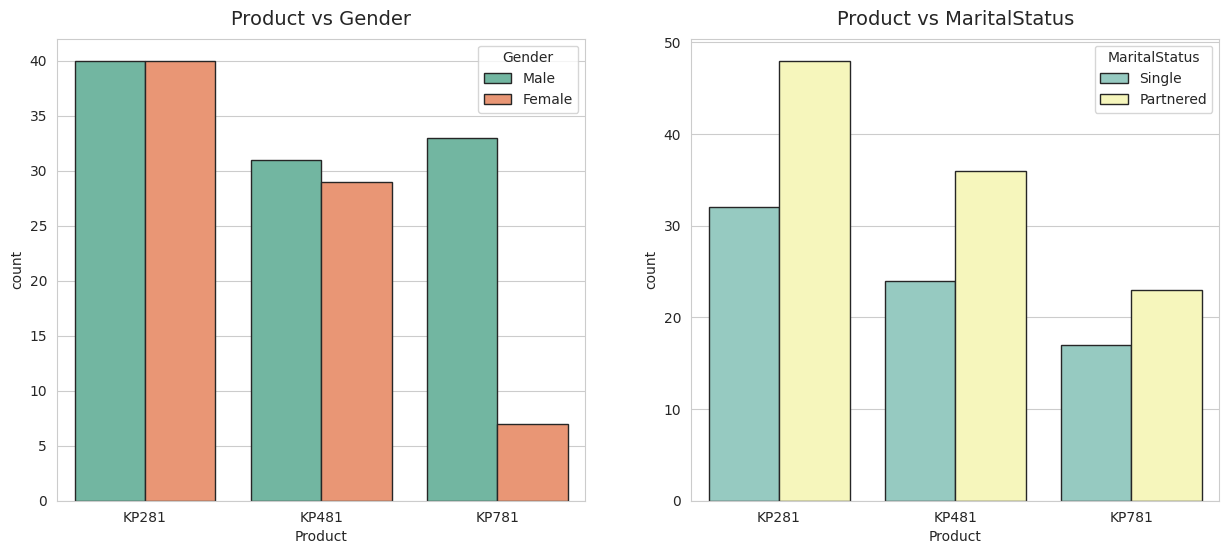

In [16]:
sns.set_style(style='whitegrid')
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
sns.countplot(data=df, x='Product', hue='Gender', edgecolor="0.15", palette='Set2', ax=axs[0])
sns.countplot(data=df, x='Product', hue='MaritalStatus', edgecolor="0.15", palette='Set3', ax=axs[1])
axs[0].set_title("Product vs Gender", pad=10, fontsize=14)
axs[1].set_title("Product vs MaritalStatus", pad=10, fontsize=14)
plt.show()

#### Obervations

- **`Product vs Gender`**
    - Equal number of males and females have purchased **KP281** product and Almost same for the product **KP481**
    - Most of the `Male` customers have purchased the **KP781** product.
    
    
- **`Product vs MaritalStatus`**
    - Customer who is `Partnered`, is more likely to purchase the product.

##### &emsp;Checking if following features have any effect on the product purchased:

1. Age
2. Education
3. Usage
4. Fitness
5. Income
6. Miles

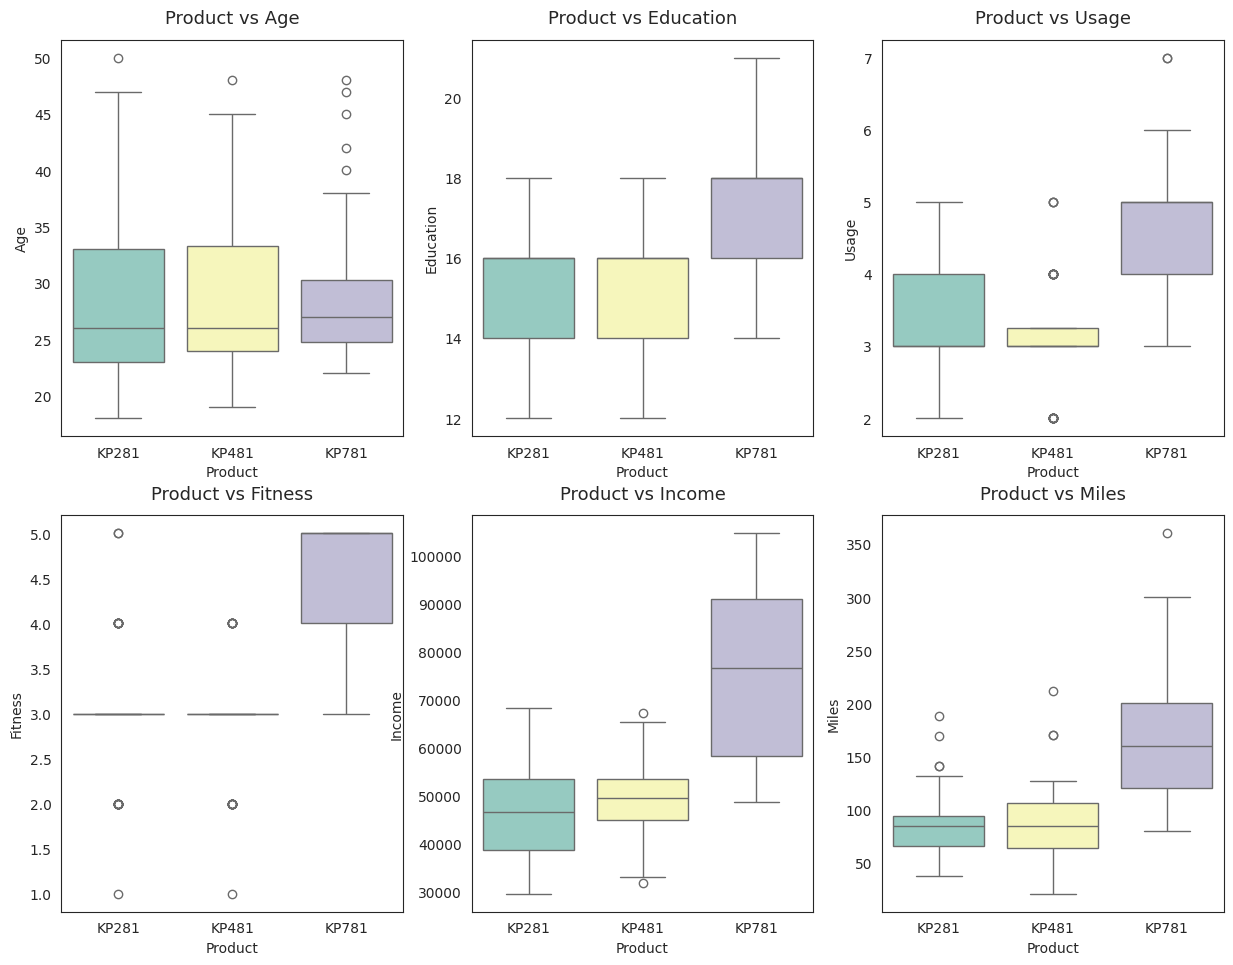

In [17]:
attrs = ['Age', 'Education', 'Usage', 'Fitness', 'Income', 'Miles']
sns.set_style("white")
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15,8))
fig.subplots_adjust(top=1.2)
count = 0
for i in range(2):
    for j in range(3):
        sns.boxplot(data=df, x='Product', y=attrs[count], ax=axs[i,j], palette='Set3')
        axs[i,j].set_title(f"Product vs {attrs[count]}", pad=12, fontsize=13)
        count += 1

#### Observations

1. **`Product vs Age`**
    * Customers purchasing products `KP281 & KP481` are having same `Age` median value.
    * Customers whose age lies between 25-30, are more likely to buy `KP781` product


2. **`Product vs Education`**
    * Customers whose `Education` is greater than 16, have more chances to purchase the `KP781` product.
    * While the customers with `Education` less than 16 have equal chances of purchasing `KP281` or `KP481`.
    
    
3. **`Product vs Usage`**
    * Customers who are planning to use the treadmill greater than 4 times a week, are more likely to purchase the `KP781` product.
    * While the other customers are likely to purchasing `KP281` or `KP481`.
    

4. **`Product vs Fitness`**
    * The more the customer is fit (fitness >= 3), higher the chances of the customer to purchase the `KP781` product.
    

5. **`Product vs Income`**
    * Higher the `Income` of the customer (Income >= 60000), higher the chances of the customer to purchase the `KP781` product.
    

6. **`Product vs Miles`**
    * If the customer expects to walk/run greater than 120 Miles per week, it is more likely that the customer will buy `KP781` product.

##  5.Multivariate Analysis

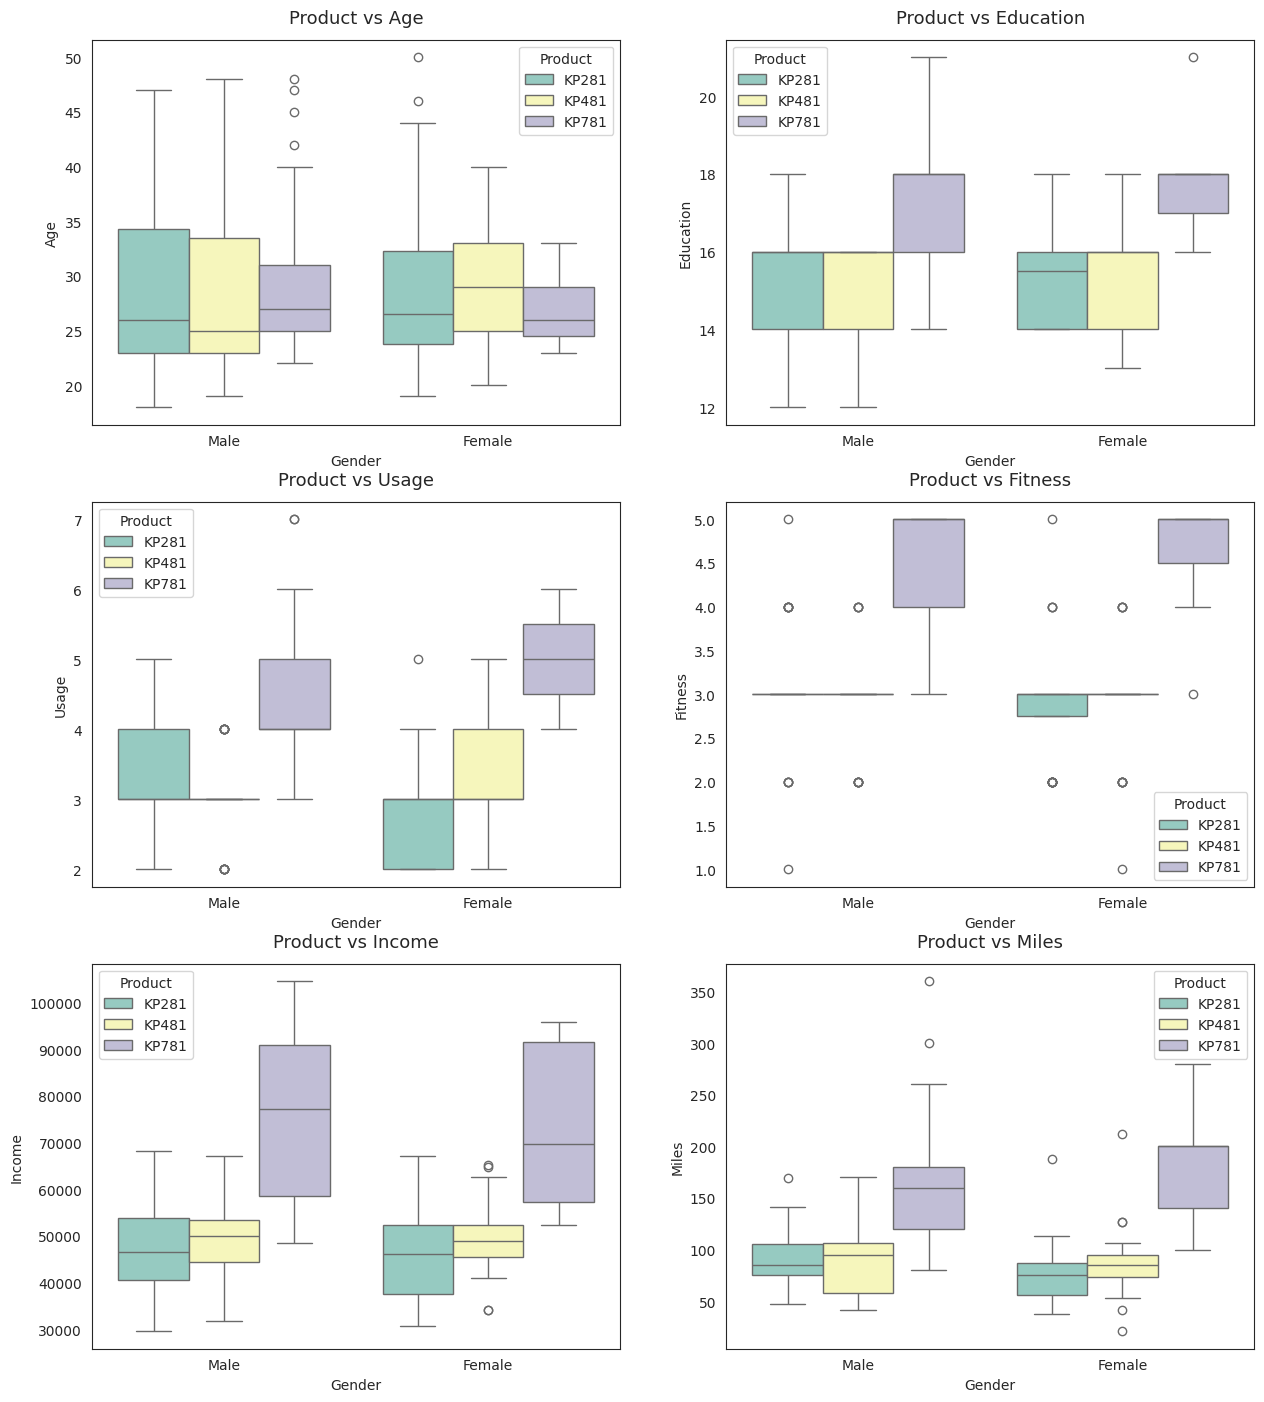

In [18]:
attrs = ['Age', 'Education', 'Usage', 'Fitness', 'Income', 'Miles']
sns.set_style("white")
fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(15,11))
fig.subplots_adjust(top=1.3)
count = 0
for i in range(3):
    for j in range(2):
        sns.boxplot(data=df, x='Gender', y=attrs[count], hue='Product', ax=axs[i,j], palette='Set3')
        axs[i,j].set_title(f"Product vs {attrs[count]}", pad=12, fontsize=13)
        count += 1

#### Obervations

- Females planning to use treadmill 3-4 times a week, are more likely to buy `KP481` product

##  Pairplot

In [19]:
df_copy = copy.deepcopy(df)

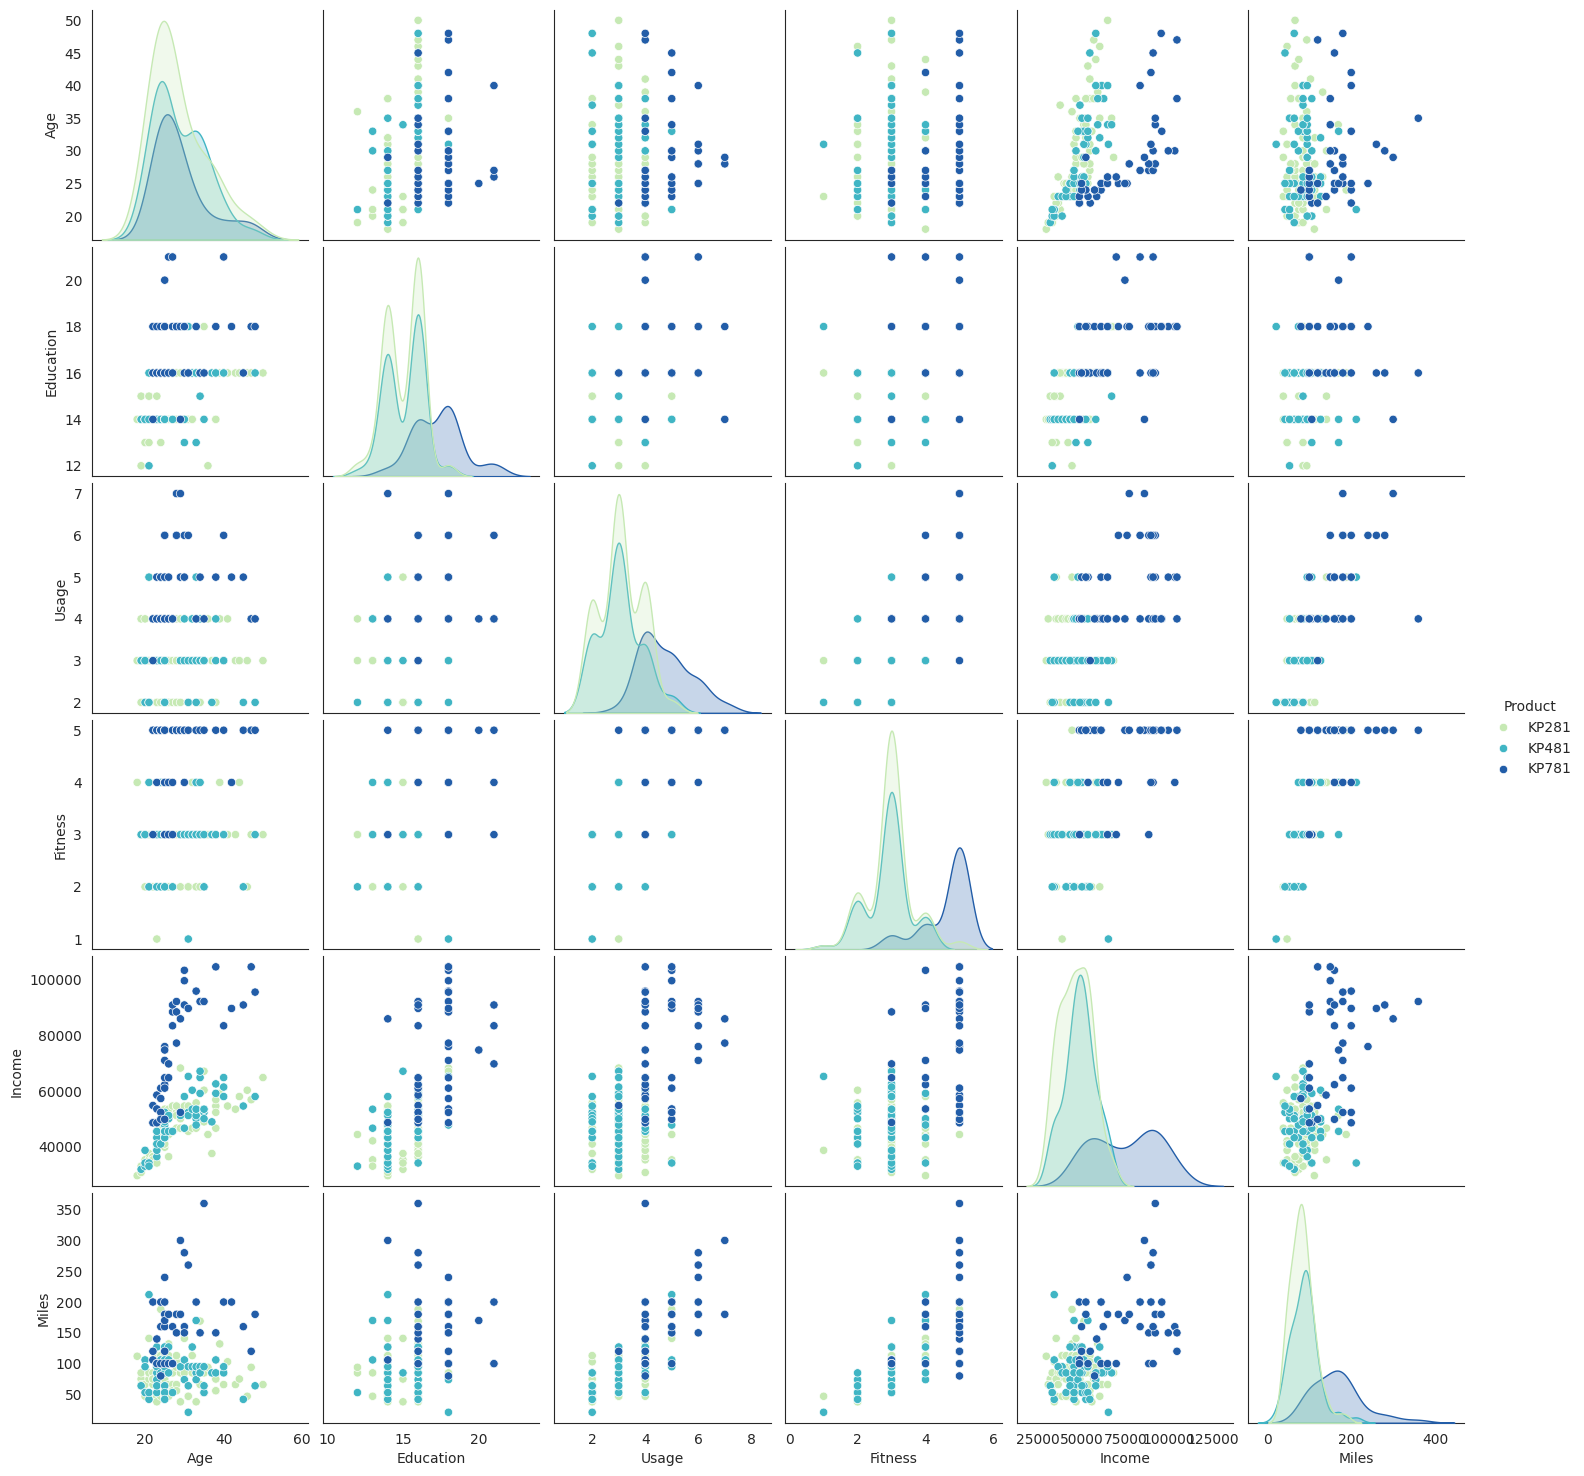

In [20]:
sns.pairplot(df_copy, hue ='Product', palette= 'YlGnBu')
plt.show()

In [21]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Product        180 non-null    object
 1   Age            180 non-null    int64 
 2   Gender         180 non-null    object
 3   Education      180 non-null    int64 
 4   MaritalStatus  180 non-null    object
 5   Usage          180 non-null    int64 
 6   Fitness        180 non-null    int64 
 7   Income         180 non-null    int64 
 8   Miles          180 non-null    int64 
dtypes: int64(6), object(3)
memory usage: 12.8+ KB


## 6. Computing Probability - Marginal, Conditional Probability

## 6.1 Probability of product purchase with respect to gender

In [22]:
pd.crosstab(index =df['Product'],columns = df['Gender'],margins = True,normalize = True ).round(2)

Gender,Female,Male,All
Product,,,
KP281,0.22,0.22,0.44
KP481,0.16,0.17,0.33
KP781,0.04,0.18,0.22
All,0.42,0.58,1.00


###  Insights

1. The **Probability** of a treadmill being purchased by a **female is 42%**.

    - **The conditional probability** of purchasing the treadmill model given that the customer is **female** is
    
        - For Treadmill model KP281 - **22%**
    
        - For Treadmill model KP481 - **16%**
    
        - For Treadmill model KP781 - **4%**


2. The **Probability** of a treadmill being purchased by a **male is 58%**.

    - **The conditional probability** of purchasing the treadmill model given that the customer is **male** is -

        - For Treadmill model KP281 - **22%**
    
        - For Treadmill model KP481 - **17%**
    
        - For Treadmill model KP781 - **18%**

## 6.2 Probability of product purchase w.r.t. Age

In [23]:
pd.crosstab(index =df['Product'],columns = df['Age'],margins = True,normalize = True ).round(2)

Age,18,19,20,21,22,23,24,25,26,27,...,41,42,43,44,45,46,47,48,50,All
Product,,,,,,,,,,,,,,,,,,,,,
KP281,0.01,0.02,0.01,0.02,0.02,0.04,0.03,0.04,0.04,0.02,...,0.01,0.00,0.01,0.01,0.00,0.01,0.01,0.00,0.01,0.44
KP481,0.00,0.01,0.02,0.02,0.00,0.04,0.02,0.06,0.02,0.01,...,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.01,0.00,0.33
KP781,0.00,0.00,0.00,0.00,0.02,0.02,0.02,0.04,0.01,0.02,...,0.00,0.01,0.00,0.00,0.01,0.00,0.01,0.01,0.00,0.22
All,0.01,0.02,0.03,0.04,0.04,0.10,0.07,0.14,0.07,0.04,...,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,1.00


NOTE:From the above we can see that it is difficult to calculate probability among different age groups so lets create some bins for different age groups according to the range of age values and analyze.Similarly for other colums as well

## Adding new columns for better analysis

- Creating New Column and Categorizing values in Age,Education,Income and Miles to different classes for better visualization

1. Young Adult: from 18 - 25
2. Adults: from 26 - 35
3. Middle Aged Adults: 36-45
4. Elder :46 and above



In [24]:
bin_range1 = [17,25,35,45,float('inf')]
bin_labels1 = ['Young Adults', 'Adults', 'Middle Aged', 'Elder']
df_copy['Age_group'] = pd.cut(df_copy['Age'],bins = bin_range1,labels = bin_labels1)

In [25]:
pd.crosstab(index =df_copy['Product'],columns = df_copy['Age_group'],margins = True,normalize = True ).round(2)

Age_group,Young Adults,Adults,Middle Aged,Elder,All
Product,,,,,
KP281,0.19,0.18,0.06,0.02,0.44
KP481,0.16,0.13,0.04,0.01,0.33
KP781,0.09,0.09,0.02,0.01,0.22
All,0.44,0.41,0.12,0.03,1.00


###  Insights

1. The **Probability** of a treadmill being purchased by a **`Young Adult(18-25) is 44%`**.

    - **The conditional probability** of purchasing the treadmill model given that the customer is **`Young Adult`** is
    
        - For Treadmill model KP281 - **19%**
    
        - For Treadmill model KP481 - **16%**
    
        - For Treadmill model KP781 - **9%**


2. The **Probability** of a treadmill being purchased by a **`Adult(26-35) is 41%`**.

    - **The conditional probability** of purchasing the treadmill model given that the customer is **`Adult`** is -

        - For Treadmill model KP281 - **18%**
    
        - For Treadmill model KP481 - **13%**
    
        - For Treadmill model KP781 - **9%**
        
        
3. The **Probability** of a treadmill being purchased by a **Middle Aged(36-45) is 12%**.
        
        
4. The **Probability** of a treadmill being purchased by a **Elder(Above 45) is only 3%**.

## 6.3 Probability of product purchase w.r.t. Education level

#### Education Column

- Categorizing the values in education column in 3 different buckets:

1. Primary Education: upto 12
2. Secondary Education: 13 to 15
3. Higher Education: 16 and above



In [26]:
bin_range2 = [0,12,15,float('inf')]
bin_labels2 = ['Primary Education', 'Secondary Education', 'Higher Education']
df_copy['Edu_group'] = pd.cut(df_copy['Education'],bins = bin_range2,labels = bin_labels2)

In [27]:
pd.crosstab(index =df_copy['Product'],columns = df_copy['Edu_group'],margins = True,normalize = True ).round(2)

Edu_group,Primary Education,Secondary Education,Higher Education,All
Product,,,,
KP281,0.01,0.21,0.23,0.44
KP481,0.01,0.14,0.18,0.33
KP781,0.00,0.01,0.21,0.22
All,0.02,0.36,0.62,1.00


###  Insights

1. The **`Probability`** of a treadmill being purchased by a customer with **`Higher Education(Above 15 Years) is 62%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`Higher Education`** is
    
        - For Treadmill model KP281 - **23%**
    
        - For Treadmill model KP481 - **18%**
    
        - For Treadmill model KP781 - **21%**


2. The **`Probability`** of a treadmill being purchased by a customer with **`Secondary Education(13-15 yrs) is 36%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`Secondary Education`** is -

        - For Treadmill model KP281 - **21%**
    
        - For Treadmill model KP481 - **14%**
    
        - For Treadmill model KP781 - **1%**
        
        
3. The **`Probability`** of a treadmill being purchased by a customer with **`Primary Education(0 to 12 yrs) is only 2%`**.

## 6.4 Probability of product purchase w.r.t. Income

#### Income Column

- Categorizing the values in Income column in 4 different buckets:

1. Low Income - Upto 40,000
2. Moderate Income - 40,000 to 60,000
3. High Income - 60,000 to 80,000
4. Very High Income - Above 80,000



In [28]:
bin_range3 = [0,40000,60000,80000,float('inf')]
bin_labels3 = ['Low Income','Moderate Income','High Income','Very High Income']
df_copy['Income_group'] = pd.cut(df_copy['Income'],bins = bin_range3,labels = bin_labels3)

In [29]:
pd.crosstab(index =df_copy['Product'],columns = df_copy['Income_group'],margins = True,normalize = True ).round(2)

Income_group,Low Income,Moderate Income,High Income,Very High Income,All
Product,,,,,
KP281,0.13,0.28,0.03,0.00,0.44
KP481,0.05,0.24,0.04,0.00,0.33
KP781,0.00,0.06,0.06,0.11,0.22
All,0.18,0.59,0.13,0.11,1.00


##  Insights

1. The **`Probability`** of a treadmill being purchased by a customer with **`Low Income(<40k) is 18%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`Low Income`** is  -
        - For Treadmill model KP281 - **13%**
    
        - For Treadmill model KP481 - **5%**
    
        - For Treadmill model KP781 - **0%**
        
        
2. The **`Probability`** of a treadmill being purchased by a customer with **`Moderate Income(40k - 60k) is 59%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`Moderate Income`** is  -
        - For Treadmill model KP281 - **28%**
    
        - For Treadmill model KP481 - **24%**
    
        - For Treadmill model KP781 - **6%**
        

3. The **`Probability`** of a treadmill being purchased by a customer with **`High Income(60k - 80k) is 13%`**

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`High Income`** is  -
    
        - For Treadmill model KP281 - **3%**
    
        - For Treadmill model KP481 - **4%**
    
        - For Treadmill model KP781 - **6%**
        
        
4. The **`Probability`** of a treadmill being purchased by a customer with **`Very High Income(>80k) is 11%`**

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`High Income`** is  -
    
        - For Treadmill model KP281 - **0%**
    
        - For Treadmill model KP481 - **0%**
    

## 6.5 Probability of product purchase w.r.t. weekly mileage

#### Miles column

- Categorizing the values in miles column in 4 different buckets:

1. Light Activity - Upto 50 miles
2. Moderate Activity - 51 to 100 miles
3. Active Lifestyle - 101 to 200 miles
4. Fitness Enthusiast - Above 200 miles

In [30]:
bin_range4 = [0,50,100,200,float('inf')]
bin_labels4 = ['Light Activity', 'Moderate Activity', 'Active Lifestyle', 'Fitness Enthusiast ']
df_copy['Miles_group'] = pd.cut(df_copy['Miles'],bins = bin_range4,labels = bin_labels4)

In [31]:
pd.crosstab(index =df_copy['Product'],columns = df_copy['Miles_group'],margins = True,normalize = True ).round(2)

Miles_group,Light Activity,Moderate Activity,Active Lifestyle,Fitness Enthusiast,All
Product,,,,,
KP281,0.07,0.28,0.10,0.00,0.44
KP481,0.03,0.22,0.08,0.01,0.33
KP781,0.00,0.04,0.15,0.03,0.22
All,0.09,0.54,0.33,0.03,1.00


###  Insights

1. The **`Probability`** of a treadmill being purchased by a customer with lifestyle of **`Light Activity(0 to 50 miles/week) is 9%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`Light Activity Lifestyle`** is  -
        
        - For Treadmill model KP281 - **7%**
    
        - For Treadmill model KP481 - **3%**
    
        - For Treadmill model KP781 - **0%**
        
        
2. The **`Probability`** of a treadmill being purchased by a customer with lifestyle of **`Moderate Activity(51 to 100 miles/week) is 54%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer with lifestyle of **`Moderate Activity`** is  -
        - For Treadmill model KP281 - **28%**
    
        - For Treadmill model KP481 - **22%**
    
        - For Treadmill model KP781 - **4%**
        

2. The **`Probability`** of a treadmill being purchased by a customer has **`Active Lifestyle(100 to 200 miles/week) is 33%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`Active Lifestyle`** is  -
        - For Treadmill model KP281 - **10%**
    
        - For Treadmill model KP481 - **8%**
    
        - For Treadmill model KP781 - **15%**
        
        
4. The **`Probability`** of a treadmill being purchased by a customer who is **`Fitness Enthusiast(>200 miles/week) is 3% only`**

## 6.6 Probability of product purchase w.r.t. Marital Status

In [32]:
pd.crosstab(index =df['Product'],columns = df['MaritalStatus'],margins = True,normalize = True ).round(2)

MaritalStatus,Partnered,Single,All
Product,,,
KP281,0.27,0.18,0.44
KP481,0.20,0.13,0.33
KP781,0.13,0.09,0.22
All,0.59,0.41,1.00


### Insights

1. The **`Probability`** of a treadmill being purchased by a **`Married Customer is 59%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer is **`Married`** is
    
        - For Treadmill model KP281 - **27%**
    
        - For Treadmill model KP481 - **20%**
    
        - For Treadmill model KP781 - **13%**


2. The **`Probability`** of a treadmill being purchased by a **`Unmarried Customer is 41%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer is **`Unmarried`** is -

        - For Treadmill model KP281 - **18%**
    
        - For Treadmill model KP481 - **13%**
    
        - For Treadmill model KP781 - **9%**

## 6.7 Probability of product purchase w.r.t. Weekly Usage

In [33]:
pd.crosstab(index =df['Product'],columns = df['Usage'],margins = True,normalize = True ).round(2)

Usage,2,3,4,5,6,7,All
Product,,,,,,,
KP281,0.11,0.21,0.12,0.01,0.00,0.00,0.44
KP481,0.08,0.17,0.07,0.02,0.00,0.00,0.33
KP781,0.00,0.01,0.10,0.07,0.04,0.01,0.22
All,0.18,0.38,0.29,0.09,0.04,0.01,1.00


### Insights

1. The **`Probability`** of a treadmill being purchased by a customer with **`Usage 3 per week is 38%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`Usage 3 per week`** is  -
        - For Treadmill model KP281 - **21%**
    
        - For Treadmill model KP481 - **17%**
    
        - For Treadmill model KP781 - **1%**
        
        
2. The **`Probability`** of a treadmill being purchased by a customer with **`Usage 4 per week is 29%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`Usage 4 per week`** is  -
        - For Treadmill model KP281 - **12%**
    
        - For Treadmill model KP481 - **7%**
    
        - For Treadmill model KP781 - **10%**

3. The **`Probability`** of a treadmill being purchased by a customer with **`Usage 2 per week is 18%`**

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`Usage 2 per week`** is  -
        - For Treadmill model KP281 - **11%**
    
        - For Treadmill model KP481 - **8%**
    
        - For Treadmill model KP781 - **0%**
        

## 6.8 Probability of product purchase w.r.t. Customer Fitness

In [34]:
pd.crosstab(index =df['Product'],columns = df['Fitness'],margins = True,normalize = True ).round(2)

Fitness,1,2,3,4,5,All
Product,,,,,,
KP281,0.01,0.08,0.30,0.05,0.01,0.44
KP481,0.01,0.07,0.22,0.04,0.00,0.33
KP781,0.00,0.00,0.02,0.04,0.16,0.22
All,0.01,0.14,0.54,0.13,0.17,1.00


###Insights

1. The **`Probability`** of a treadmill being purchased by a customer with **`Average(3) Fitness is 54%`**.

    - **`The conditional probability`** of purchasing the treadmill model given that the customer has **`Average Fitness`** is  -
        - For Treadmill model KP281 - **30%**
    
        - For Treadmill model KP481 - **22%**
    
        - For Treadmill model KP781 - **2%**
        

2. The **`Probability`** of a treadmill being purchased by a customer with **`Fitness of 2,4,5 is almost 15%`**.


3. The **`Probability`** of a treadmill being purchased by a customer with **`very low(1) Fitness is only 1%`**.

# 7. Customer Profiling

Based on above analysis

- Probability of purchase of KP281 = 44%
- Probability of purchase of KP481 = 33%
- Probability of purchase of KP781 = 22%

- `Customer Profile` for `KP281` Treadmill:

    - Age of customer mainly between 18 to 35 years  with few between 35 to 50 years
    - Education level of customer 13 years and above
    - Annual Income of customer below USD 60,000
    - Weekly Usage - 2 to 4 times
    - Fitness Scale - 2 to 4
    - Weekly Running Mileage - 50 to 100 miles
    
    
- `Customer Profile` for `KP481` Treadmill:

    - Age of customer mainly between 18 to 35 years  with few between 35 to 50 years
    - Education level of customer 13 years and above
    - Annual Income of customer between USD 40,000 to USD 80,000
    - Weekly Usage - 2 to 4 times
    - Fitness Scale - 2 to 4
    - Weekly Running Mileage - 50 to 200 miles


- `Customer Profile` for `KP781` Treadmill:

    - Gender - Male
    - Age of customer between 18 to 35 years
    - Education level of customer 15 years and above
    - Annual Income of customer USD 80,000 and above
    - Weekly Usage - 4 to 7 times
    - Fitness Scale - 3 to 5
    - Weekly Running Mileage - 100 miles and above

# 8. Recommendations

**Marketing Campaigns for KP781**

- The KP784 model exhibits a significant sales disparity in terms of gender, with only 18% of total sales attributed to female customers. To enhance this metric, it is recommended to implement targeted strategies such as offering special promotions and trials exclusively designed for the female customers.

**Affordable Pricing and Payment Plans**

- Given the target customer's age, education level, and income, it's important to offer the KP281 and KP481 Treadmill at an affordable price point. Additionally, consider providing flexible payment plans that allow customers to spread the cost over several months. This can make the treadmill more accessible to customers with varying budgets.

**User-Friendly App Integration**

- Create a user-friendly app that syncs with the treadmill. This app could track users' weekly running mileage, provide real-time feedback on their progress, and offer personalized recommendations for workouts based on their fitness scale and goals.This  can enhance the overall treadmill experience and keep users engaged.